In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
from scipy.stats import mannwhitneyu

In [2]:
# df = pd.read_excel ('P73Gnrh-1.excel')

In [3]:
# plt.figure(figsize=(10, 6)) 
# plt.bar(x_data, y_data, color='skyblue', edgecolor='black')


In [4]:
# plt.title('Trp73 GnRH-1', fontsize=16, fontweight='bold')
# plt.xlabel('WT & KO', fontsize=12)
#plt.ylabel('No.of GnRH-1 neurons', fontsize=12)
# plt.xticks(rotation=45)  
# plt.grid(axis='y', linestyle='--', alpha=0.7)  


In [5]:
df = pd.read_csv('E13.5New.csv')
print(df)

   ID Genotype E13.5  Nose  FBJ  Brain  Total
0   1       Trp73 WT   106  142    118    366
1   2       Trp73 WT   278  116    162    556
2   3       Trp73 WT    98   50     88    236
3   4       Trp73 KO    86  142     40    268
4   5       Trp73 KO   138  246     48    432
5   6       Trp73 KO   126  102    162    390


In [6]:
wt = df[df["Genotype E13.5"].str.contains("WT")]
ko = df[df["Genotype E13.5"].str.contains("KO")]

regions = ["Nose", "FBJ", "Brain", "Total"]

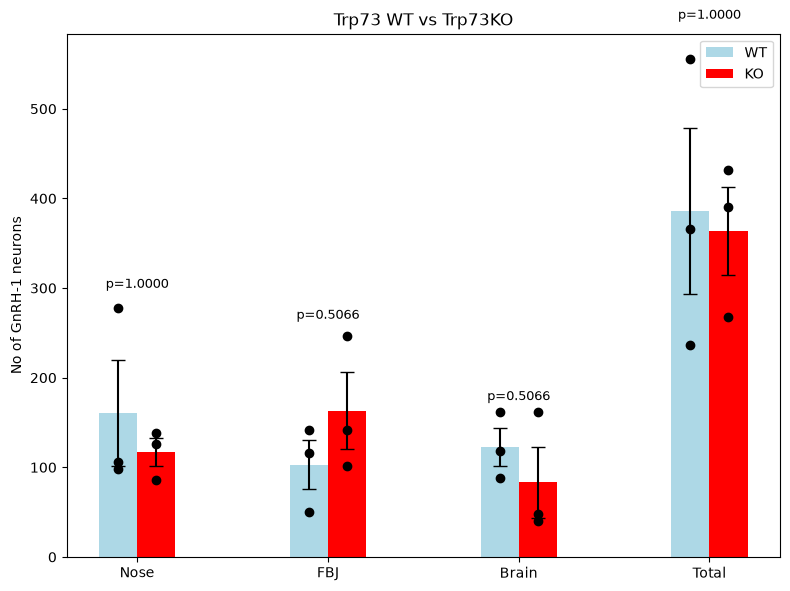

In [29]:
wt_means = []
ko_means = []

wt_sems = []
ko_sems = []

p_values = []

for region in regions:

    wt_vals = wt[region].values
    ko_vals = ko[region].values

    wt_means.append(np.mean(wt_vals))
    ko_means.append(np.mean(ko_vals))

    wt_sems.append(np.std(wt_vals, ddof=1)/np.sqrt(len(wt_vals)))
    ko_sems.append(np.std(ko_vals, ddof=1)/np.sqrt(len(ko_vals)))

    stat, p = mannwhitneyu(
        wt_vals,
        ko_vals,
        alternative='two-sided'
    )

    p_values.append(p)

# Created figure
fig, ax = plt.subplots(figsize=(8,6))

x = np.arange(len(regions))
width = 0.20

# Bar graph
ax.bar(
    x - width/2,
    wt_means,
    width,
    yerr=wt_sems,
    capsize=5,
    color='lightBlue',
    label='WT'
)

ax.bar(
    x + width/2,
    ko_means,
    width,
    yerr=ko_sems,
    capsize=5,
    color='Red',
    label='KO'
)

# Individual replicates
for i, region in enumerate(regions):

    wt_vals = wt[region].values
    ko_vals = ko[region].values

    ax.scatter(
        np.repeat(x[i]-width/2, len(wt_vals)),
        wt_vals,
        color='black',
        zorder=10
    )

    ax.scatter(
        np.repeat(x[i]+width/2, len(ko_vals)),
        ko_vals,
        color='black',
        zorder=10
    )

    # p value above bars
    ymax = max(max(wt_vals), max(ko_vals))
    ax.text(
        x[i],
        ymax + ymax*0.08,
        f"p={p_values[i]:.4f}",
        ha='center',
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels(regions)

ax.set_ylabel("No of GnRH-1 neurons")
ax.set_title("Trp73 WT vs Trp73KO")
ax.legend()

plt.tight_layout()
plt.savefig("WT_KO_AllRegions.png", dpi=300)
plt.show()

In [17]:
df = pd.read_csv('Neurons.csv')
print(df)

   Unnamed: 0 Genotype   AP2e neurons  HuCD
0           1        WT        281.00   353
1           2        KO          0.33   483


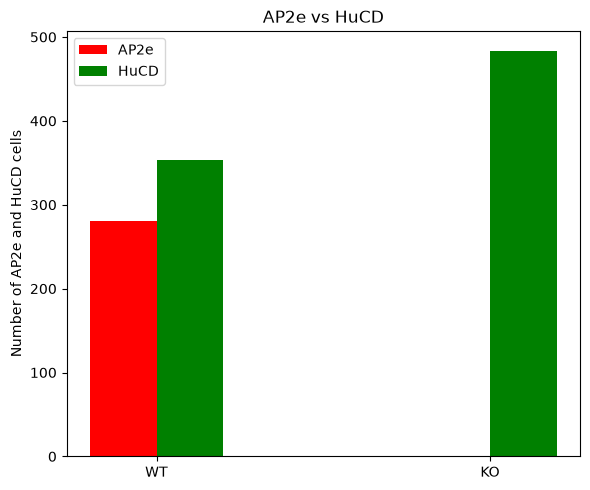

In [33]:
df.columns = [str(c).replace('\xa0', '').strip() for c in df.columns]

wt_ap2e = df.loc[df["Genotype"]=="WT", "AP2e neurons"].iloc[0]
ko_ap2e = df.loc[df["Genotype"]=="KO", "AP2e neurons"].iloc[0]

wt_hucd = df.loc[df["Genotype"]=="WT", "HuCD"].iloc[0]
ko_hucd = df.loc[df["Genotype"]=="KO", "HuCD"].iloc[0]

x = np.arange(2)
width = 0.20

fig, ax = plt.subplots(figsize=(6,5))

ax.bar(x-width/2,
       [wt_ap2e, ko_ap2e],
       width,
       label='AP2e',
       color='Red')

ax.bar(x+width/2,
       [wt_hucd, ko_hucd],
       width,
       label='HuCD',
       color='Green')

ax.set_xticks(x)
ax.set_xticklabels(['WT', 'KO'])
ax.set_ylabel('Number of AP2e and HuCD cells')
ax.set_title('AP2e vs HuCD')
ax.legend()

plt.tight_layout()
plt.savefig("Neurons.png", dpi=300)
plt.show()

